# Housing Market Model - Demonstration

### Initialisation
Initialise the simulation and run one tick.
This produces an initial list of dwellings and households, as well as the grid.

In [98]:
from housingSimulator.src.model import runSimulation
from copy import deepcopy
firstStep = runSimulation(1)
allSteps = [deepcopy(firstStep[0])]

### Grid creation and quality mapping
The simulation runs on a 50x50 grid, modelled after the Perth Metropolitan region. In order to simulate this region, areas containing water are assigned quality zero and blacked out, and areas with low crime, low social housing rates, and more affluent inhabitants are pinpointed as areas of high quality.

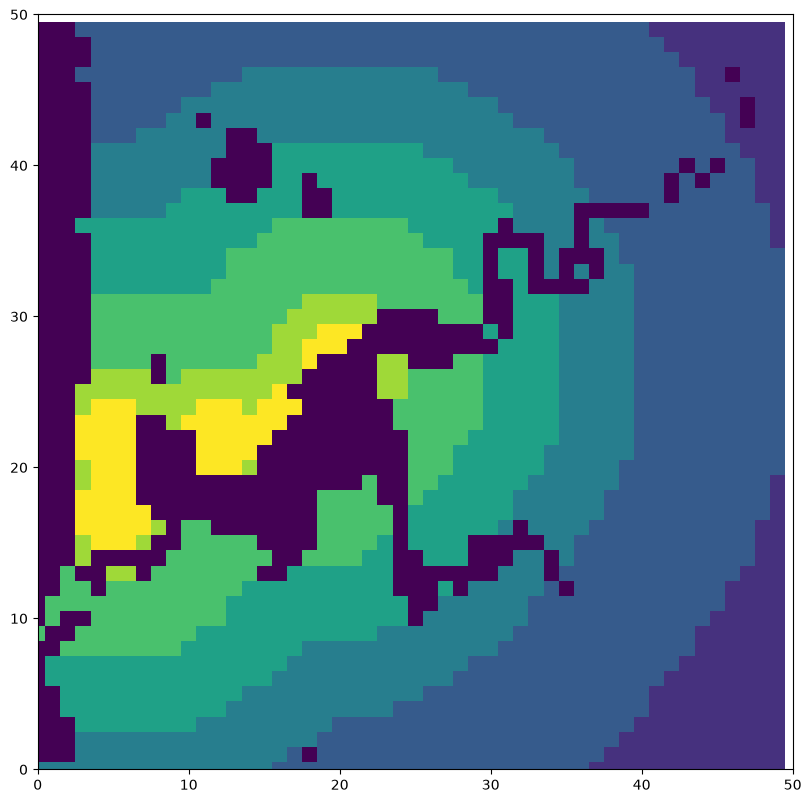

In [99]:

from housingSimulator.src.classes import Dwelling, Household, Bank
from housingSimulator.src.model import reconstructQualityGrid
from housingSimulator.src.constants import GRID_DIM
import matplotlib.pyplot as plt

# Minimal grid graphing functionality
def graphGrid(
    steps: tuple[list[Dwelling], list[Household], Bank, list[float]],
) -> None:
    qualityGrid = reconstructQualityGrid(steps[0])
    _fig, a = plt.subplots(figsize=(8, 8), constrained_layout=True)
    a.axis([0, GRID_DIM, 0, GRID_DIM])
    a.imshow(qualityGrid)
    plt.show()

graphGrid(firstStep[0])


### Initial agent state
All agents start off with no home or owned property. All houses are vacant and on the market. Every house corresponds to a coordinate. We can display vacant houses as red dots on the map, owner occupied houses as blue, and houses occupied by renters as yellow.

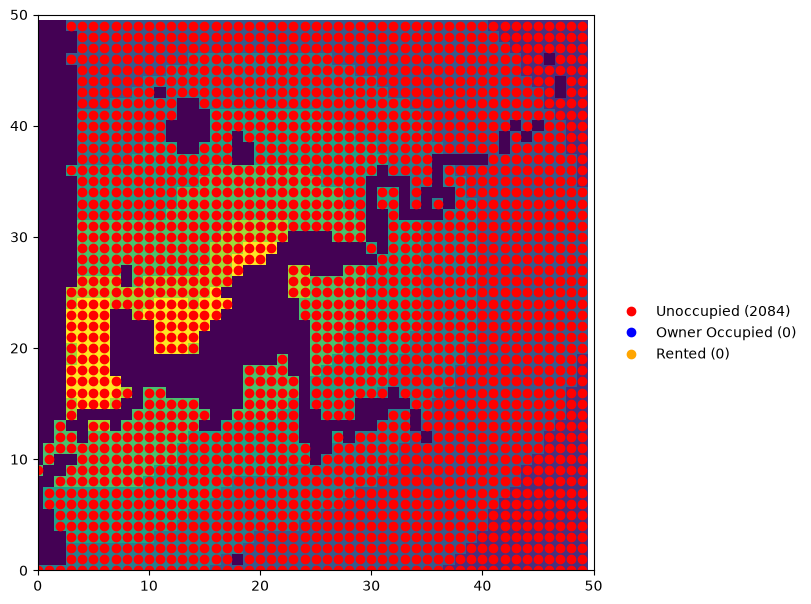

In [100]:
from housingSimulator.utils.helpers import getUnoccupiedDwellings, getOwnedDwellings, getRentedDwellings
def graphStep(
    step: tuple[list[Dwelling], list[Household], Bank, list[float]], show=bool
) -> None:
    qualityGrid = reconstructQualityGrid(step[0])
    fig, a = plt.subplots(figsize=(8, 8), constrained_layout=True)
    dwellings = step[0]
    unoccupiedCoords = [x.coord for x in getUnoccupiedDwellings(dwellings)]
    ownedCoords = [x.coord for x in getOwnedDwellings(dwellings)]
    rentedCoords = [x.coord for x in getRentedDwellings(dwellings)]
    a.clear()
    a.axis([0, GRID_DIM, 0, GRID_DIM])
    a.imshow(qualityGrid)
    xs, ys = zip(*unoccupiedCoords) if unoccupiedCoords else ([], [])
    a.plot(xs, ys, "o", color="red", label=f"Unoccupied ({len(unoccupiedCoords)})")
    xs, ys = zip(*ownedCoords) if ownedCoords else ([], [])
    a.plot(xs, ys, "o", color="blue", label=f"Owner Occupied ({len(ownedCoords)})")
    xs, ys = zip(*rentedCoords) if rentedCoords else ([], [])
    a.plot(xs, ys, "o", color="orange", label=f"Rented ({len(rentedCoords)})")
    if show:
        a.legend(loc="upper left", bbox_to_anchor=(1.02, 0.5), frameon=False)

    if show:
        plt.show()
        return None
    return fig

graphStep(firstStep[0], True)

### Agent income
Agents are allocated an income based on a logonormal distribution, with a fixed mean and sigma factor. This creates a long tailed distribution, which can be used to simulate the real world distribution of income, where most people make a similar amount, but few make an amount significantly larger than the median.
We can inspect agent's income like so:

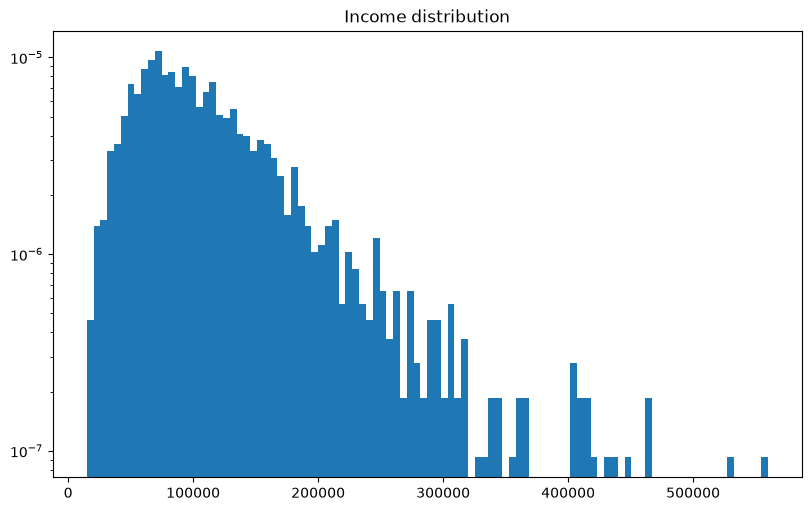

In [101]:
def graphIncome(
    step: tuple[list[Dwelling], list[Household], Bank, list[float]],
) -> None:
    _fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
    ax.set_title(f"Income distribution")
    incomes = [x.income for x in step[1]]
    ax.hist(incomes, 100, density=True, log=True)

graphIncome(firstStep[0])


### Simulate steps
Simulate steps to allow agents to purchase and move into houses. More blue dots appear on the map as more agents are able to buy houses.

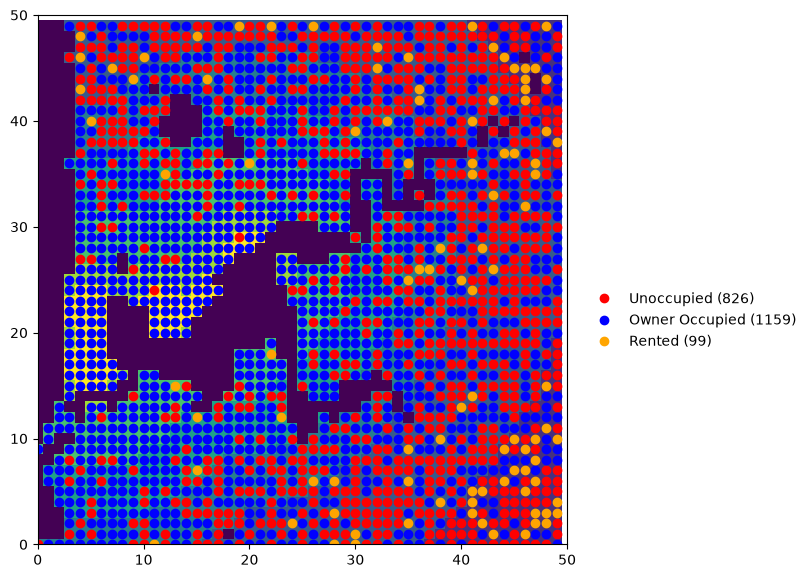

In [102]:
from housingSimulator.src.model import tick

# Step 2
dwellings, households, bank, sales = firstStep[0]

nextDwellings, nextHouseholds, nextBank = tick(dwellings, households, bank, sales)
secondStep = (nextDwellings, nextHouseholds, nextBank, [])
graphStep(secondStep, True)
allSteps.append(secondStep)

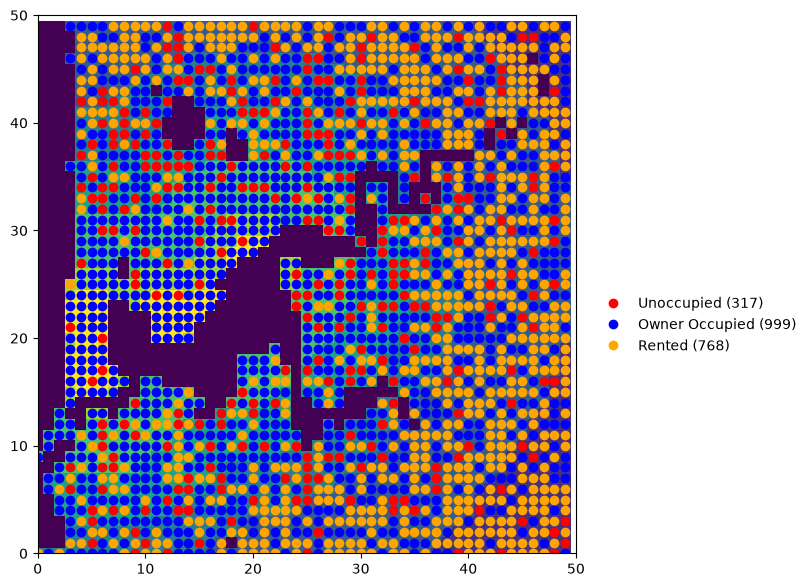

In [103]:
# Step 5
dwellings, households, bank, sales = firstStep[0]
for i in range(3):
    nextDwellings, nextHouseholds, bank = tick(dwellings, households, bank, sales)
    dwellings = nextDwellings
    households = nextHouseholds
    bank = nextBank
    allSteps.append(deepcopy((dwellings, households, bank, [])))

graphStep((dwellings, households, bank, []), True)

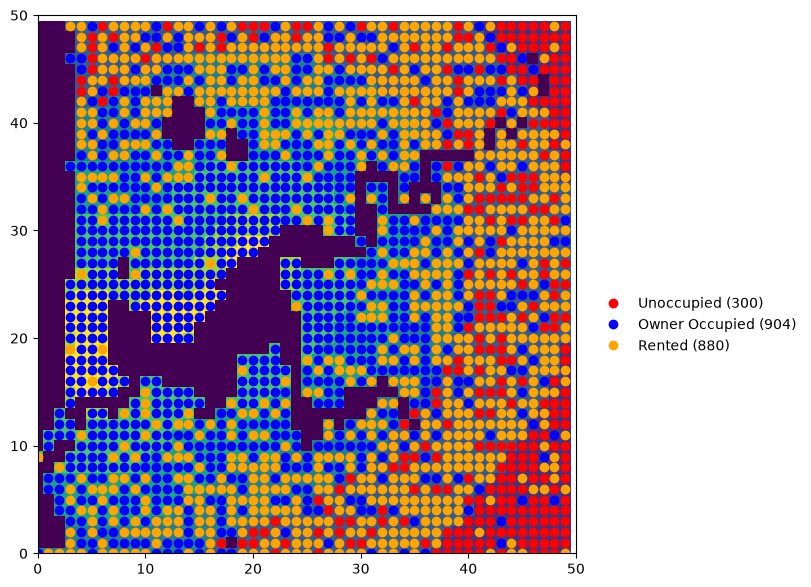

In [104]:
# Step 10
for i in range(5):
    nextDwellings, nextHouseholds, bank = tick(dwellings, households, bank, sales)
    dwellings = nextDwellings
    households = nextHouseholds
    bank = nextBank
    allSteps.append(deepcopy((dwellings, households, bank, [])))

graphStep((dwellings, households, bank, []), True)

### Examine simulation
We can see that agents initially buy houses in areas with higher quality. They then buy investment properties in areas of lower quality and rent these out to agents who cannot afford a house. These tend to be in lower quality areas. In later steps, some houses become vacant in higher quality areas that were previously owner occupied. We can plot this change historically, and create a simple animation to show the progress of our simulation over time.

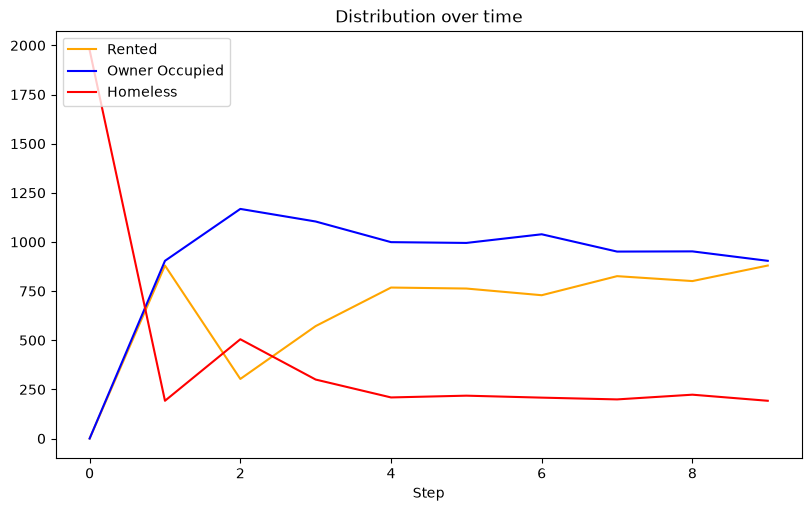

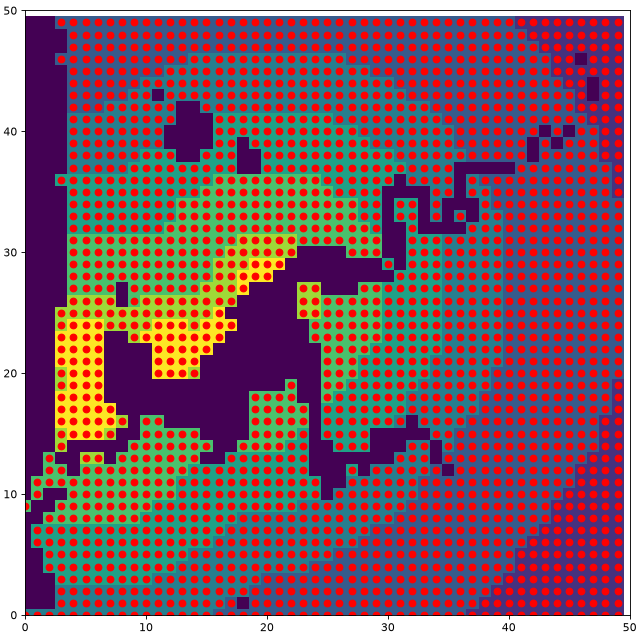

In [105]:
import io
from PIL import Image
from IPython.display import Image as IPImage, display

def graphSimulation(
    steps: list[tuple[list[Dwelling], list[Household], Bank, list[float]]],
) -> None:

    historicalRented = []
    historicalOwnerOccupied = []
    historicalHomeless = []

    _fig, d = plt.subplots(figsize=(8, 5), constrained_layout=True)

    for i, (dwellings, households, _bank, _sales) in enumerate(steps):
        # Save historical data.
        historicalRented.append(len(getRentedDwellings(dwellings)))
        historicalOwnerOccupied.append(len(getOwnedDwellings(dwellings)))
        historicalHomeless.append(sum(1 for x in households if not x.occupying))

    # Plot historical data.
    d.clear()
    d.set_title("Distribution over time")
    d.plot(historicalRented, color="orange", label="Rented")
    d.plot(historicalOwnerOccupied, color="blue", label="Owner Occupied")
    d.plot(historicalHomeless, color="red", label="Homeless")
    d.set_xlabel("Step")
    d.legend(loc="upper left")
    plt.show()

graphSimulation(allSteps)


frames = []
for step in allSteps:
    fig = graphStep(step, show=False)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=80)
    plt.close(fig)
    buf.seek(0)
    frames.append(Image.open(buf).convert("RGB"))

frames[0].save("grid.gif", save_all=True, append_images=frames[1:], duration=500, loop=0)
display(IPImage(filename="grid.gif"))